> # **2702236156 - Veron Fujimori**

### Import Libraries

In [32]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from scipy.stats import shapiro
import xgboost as xgb
import pickle
import matplotlib.pyplot as plt
import seaborn as sns

### Import Dataset

In [33]:
df = pd.read_csv('./Dataset_B_hotel.csv')

### EDA (Explanatory Data Analysis)

Attribute Information



In [34]:
df.head()

,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN00001,2,0,1,2,Meal Plan 1,0.0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00,0,Not_Canceled
1,INN00002,2,0,2,3,Not Selected,0.0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68,1,Not_Canceled
2,INN00003,1,0,2,1,Meal Plan 1,0.0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00,0,Canceled
3,INN00004,2,0,0,2,Meal Plan 1,0.0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00,0,Canceled
4,INN00005,2,0,1,1,Not Selected,0.0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50,0,Canceled


In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36275 entries, 0 to 36274
Data columns (total 19 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Booking_ID                            36275 non-null  object 
 1   no_of_adults                          36275 non-null  int64  
 2   no_of_children                        36275 non-null  int64  
 3   no_of_weekend_nights                  36275 non-null  int64  
 4   no_of_week_nights                     36275 non-null  int64  
 5   type_of_meal_plan                     35368 non-null  object 
 6   required_car_parking_space            35005 non-null  float64
 7   room_type_reserved                    36275 non-null  object 
 8   lead_time                             36275 non-null  int64  
 9   arrival_year                          36275 non-null  int64  
 10  arrival_month                         36275 non-null  int64  
 11  arrival_date   

In [36]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
no_of_adults,36275.0,1.844962,0.518715,0.0,2.0,2.00,2.000,4.0
no_of_children,36275.0,0.105279,0.402648,0.0,0.0,0.00,0.000,10.0
no_of_weekend_nights,36275.0,0.810724,0.870644,0.0,0.0,1.00,2.000,7.0
no_of_week_nights,36275.0,2.204300,1.410905,0.0,1.0,2.00,3.000,17.0
required_car_parking_space,35005.0,0.031281,0.174079,0.0,0.0,0.00,0.000,1.0
lead_time,36275.0,85.232557,85.930817,0.0,17.0,57.00,126.000,443.0
arrival_year,36275.0,2017.820427,0.383836,2017.0,2018.0,2018.00,2018.000,2018.0
arrival_month,36275.0,7.423653,3.069894,1.0,5.0,8.00,10.000,12.0
arrival_date,36275.0,15.596995,8.740447,1.0,8.0,16.00,23.000,31.0
repeated_guest,36275.0,0.025637,0.158053,0.0,0.0,0.00,0.000,1.0


Drop Kolom Tidak Berguna

In [37]:
df = df.drop(columns="Booking_ID")

Data Duplikat

In [38]:
print(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

9197


Missing Value

In [39]:
print("Sebelum Drop: ")
print(df.isnull().sum())

Sebelum Drop: 
no_of_adults                               0
no_of_children                             0
no_of_weekend_nights                       0
no_of_week_nights                          0
type_of_meal_plan                        880
required_car_parking_space              1190
room_type_reserved                         0
lead_time                                  0
arrival_year                               0
arrival_month                              0
arrival_date                               0
market_segment_type                        0
repeated_guest                             0
no_of_previous_cancellations               0
no_of_previous_bookings_not_canceled       0
avg_price_per_room                      1517
no_of_special_requests                     0
booking_status                             0
dtype: int64


In [40]:
df = df.dropna().reset_index(drop=True)
print("\nSesudah Drop:")
print(df.isnull().sum())


Sesudah Drop:
no_of_adults                            0
no_of_children                          0
no_of_weekend_nights                    0
no_of_week_nights                       0
type_of_meal_plan                       0
required_car_parking_space              0
room_type_reserved                      0
lead_time                               0
arrival_year                            0
arrival_month                           0
arrival_date                            0
market_segment_type                     0
repeated_guest                          0
no_of_previous_cancellations            0
no_of_previous_bookings_not_canceled    0
avg_price_per_room                      0
no_of_special_requests                  0
booking_status                          0
dtype: int64


Mengaktegorikan Kolom

In [41]:
cat_cols = []
num_cols = []

for i in df.columns:
    if 'int' in str(df[i].dtype) or 'float' in str(df[i].dtype):
        num_cols.append(i)
    else:
        cat_cols.append(i)

print(f'Categorical: {cat_cols}')
print(f'Numeric: {num_cols}')

Categorical: ['type_of_meal_plan', 'room_type_reserved', 'market_segment_type', 'booking_status']
Numeric: ['no_of_adults', 'no_of_children', 'no_of_weekend_nights', 'no_of_week_nights', 'required_car_parking_space', 'lead_time', 'arrival_year', 'arrival_month', 'arrival_date', 'repeated_guest', 'no_of_previous_cancellations', 'no_of_previous_bookings_not_canceled', 'avg_price_per_room', 'no_of_special_requests']


Distribusi Kolom Kategorik

In [42]:
for i in cat_cols:
    print('===========================')
    print(f'Unique: {df[i].unique()}')
    print(df[i].value_counts())
print('===========================')

Unique: ['Meal Plan 1' 'Not Selected' 'Meal Plan 2' 'Meal Plan 3']
type_of_meal_plan
Meal Plan 1     18513
Not Selected     4055
Meal Plan 2      1057
Meal Plan 3         5
Name: count, dtype: int64
Unique: ['Room_Type 1' 'Room_Type 4' 'Room_Type 2' 'Room_Type 6' 'Room_Type 5'
 'Room_Type 7' 'Room_Type 3']
room_type_reserved
Room_Type 1    16997
Room_Type 4     4908
Room_Type 6      847
Room_Type 2      527
Room_Type 5      210
Room_Type 7      135
Room_Type 3        6
Name: count, dtype: int64
Unique: ['Offline' 'Online' 'Corporate' 'Complementary' 'Aviation']
market_segment_type
Online           18153
Offline           3797
Corporate         1262
Complementary      328
Aviation            90
Name: count, dtype: int64
Unique: ['Not_Canceled' 'Canceled']
booking_status
Not_Canceled    16852
Canceled         6778
Name: count, dtype: int64


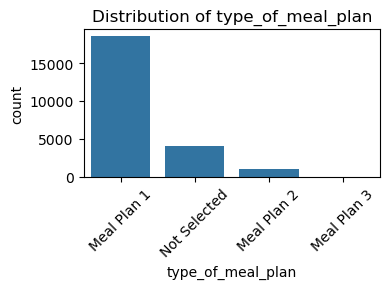

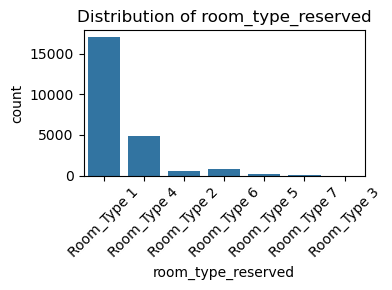

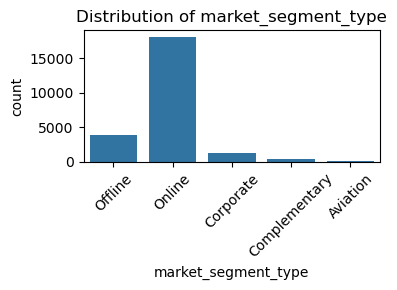

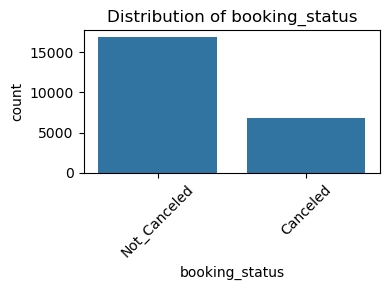

In [43]:
def checking_distribution_categorical(df, cat_cols):
    for column in cat_cols:
        plt.figure(figsize=(4, 3))  
        sns.countplot(data=df, x=column)
        plt.title(f"Distribution of {column}")
        plt.xticks(rotation=45) 
        plt.tight_layout()  
        plt.show()

checking_distribution_categorical(df, cat_cols)

Distribusi Kolom Numeric

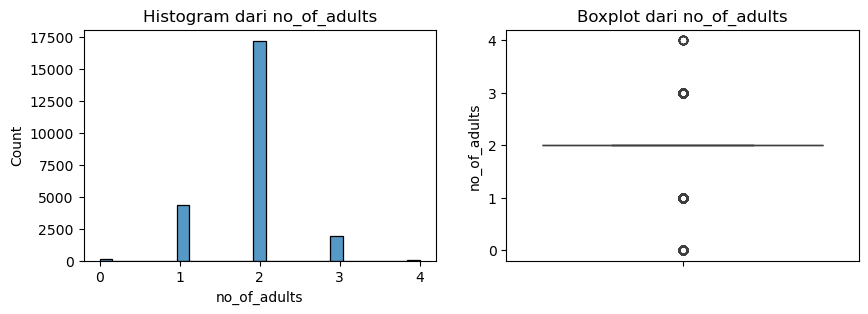

no_of_adults - Skewness: -0.2999152356946826
no_of_adults - Kurtosis: 1.1100516095174395


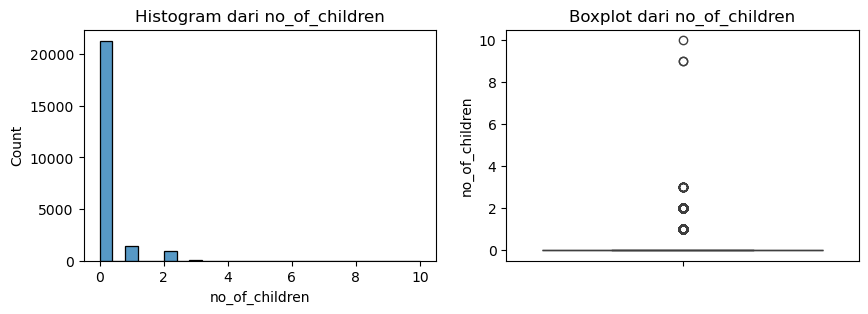

no_of_children - Skewness: 4.104433818603448
no_of_children - Kurtosis: 29.557213582659053


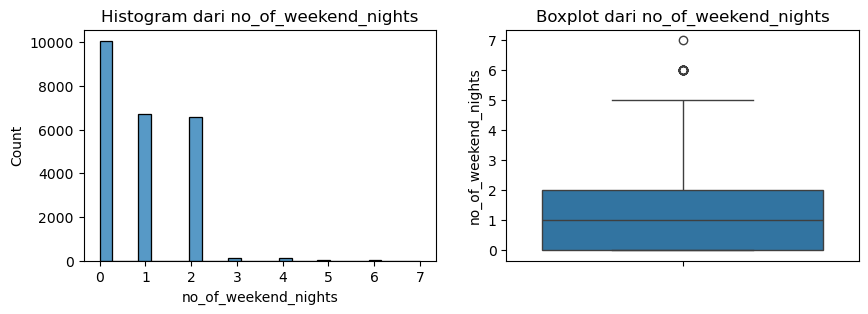

no_of_weekend_nights - Skewness: 0.6632423864629869
no_of_weekend_nights - Kurtosis: 0.37626614091695565


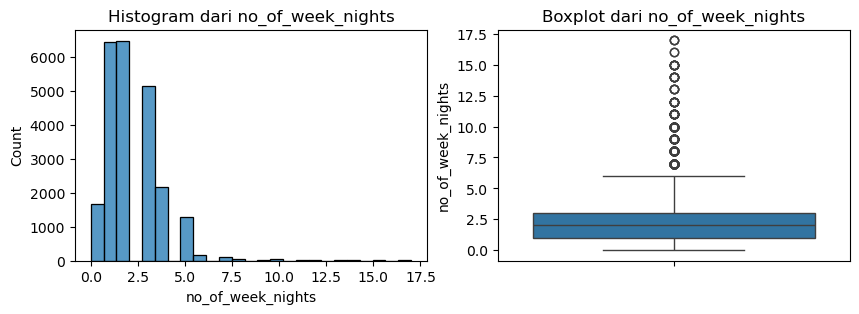

no_of_week_nights - Skewness: 1.6264419947726958
no_of_week_nights - Kurtosis: 7.404382587639077


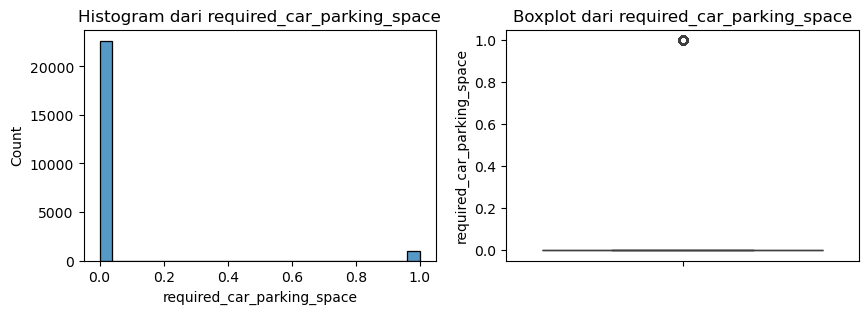

required_car_parking_space - Skewness: 4.610514846087
required_car_parking_space - Kurtosis: 19.258477141127713


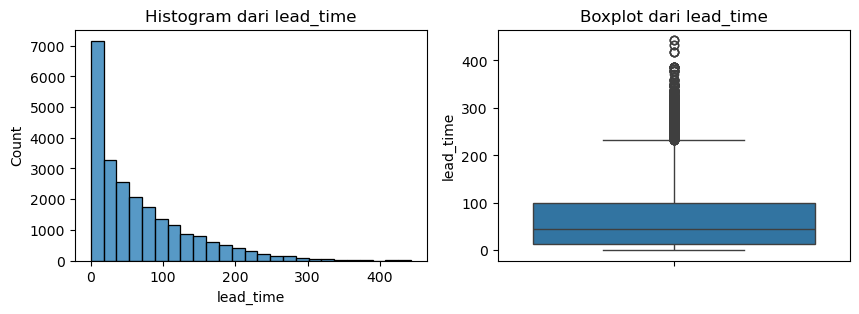

lead_time - Skewness: 1.4057189675092234
lead_time - Kurtosis: 1.8678431724695441


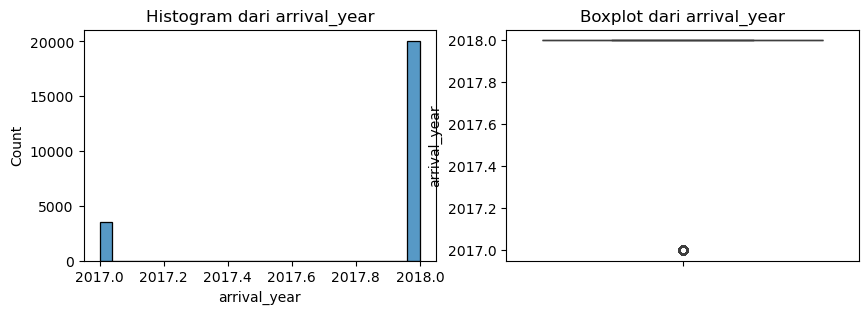

arrival_year - Skewness: -1.956108239287647
arrival_year - Kurtosis: 1.8265140294543123


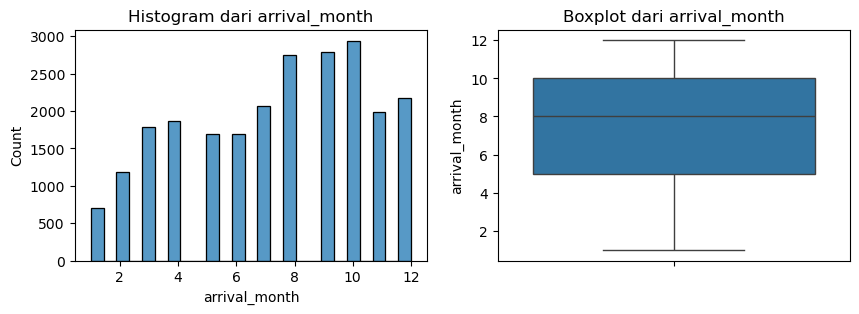

arrival_month - Skewness: -0.29363995953902794
arrival_month - Kurtosis: -1.0021960062350965


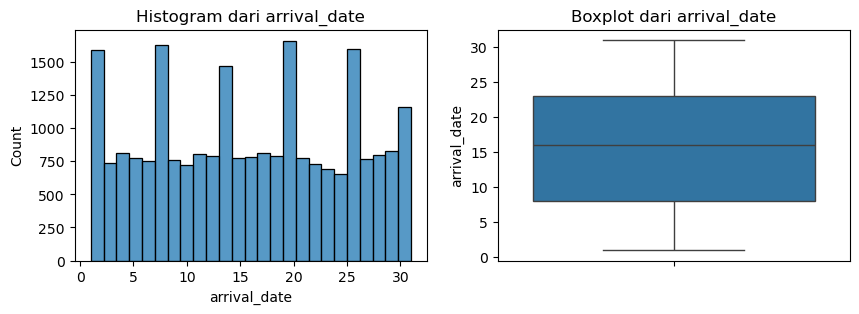

arrival_date - Skewness: 0.012584958616689148
arrival_date - Kurtosis: -1.2003932708939595


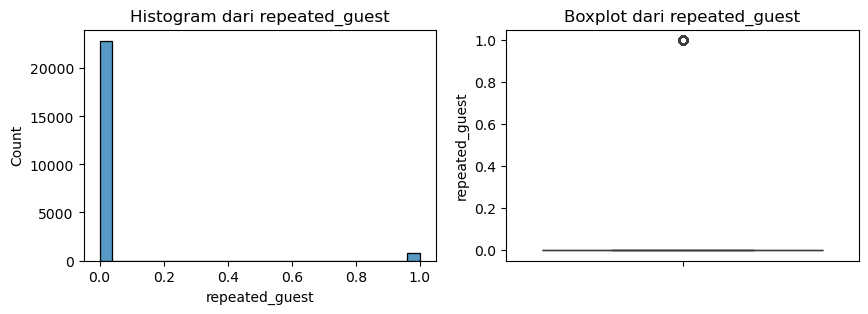

repeated_guest - Skewness: 5.299819882026321
repeated_guest - Kurtosis: 26.0902990099758


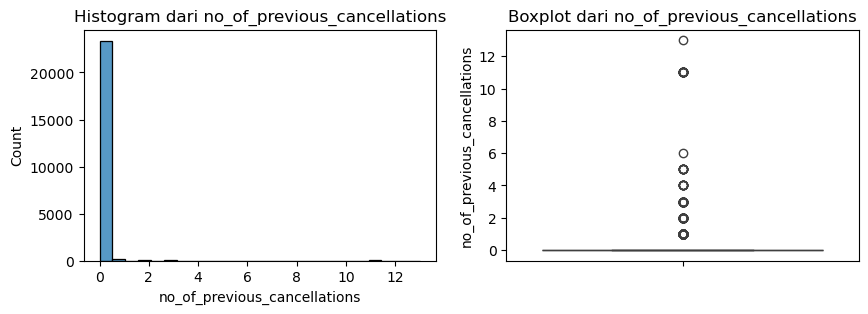

no_of_previous_cancellations - Skewness: 22.182508824685847
no_of_previous_cancellations - Kurtosis: 560.2865765722249


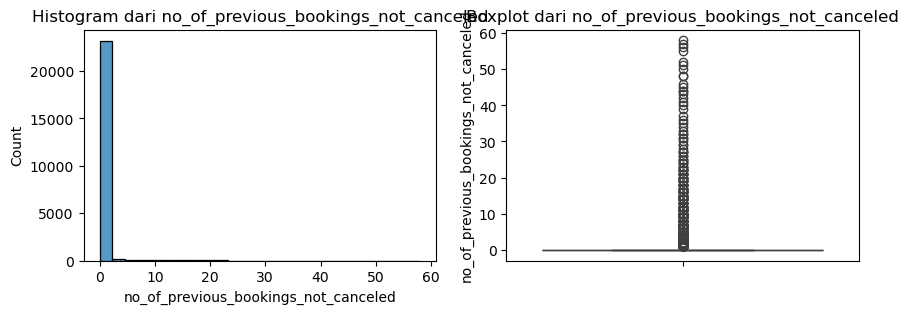

no_of_previous_bookings_not_canceled - Skewness: 16.428652159046262
no_of_previous_bookings_not_canceled - Kurtosis: 336.0877298492529


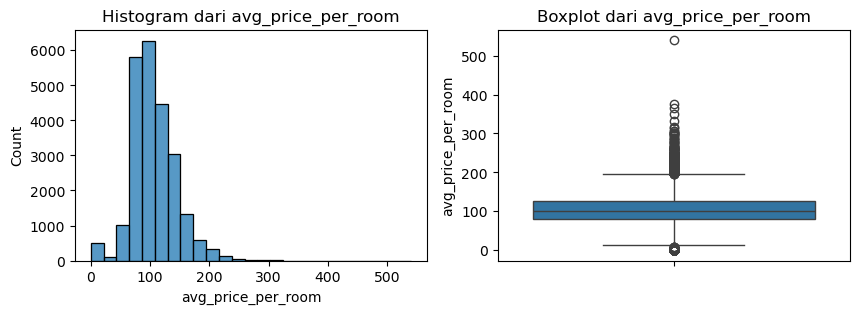

avg_price_per_room - Skewness: 0.5857365565249829
avg_price_per_room - Kurtosis: 2.693485090930711


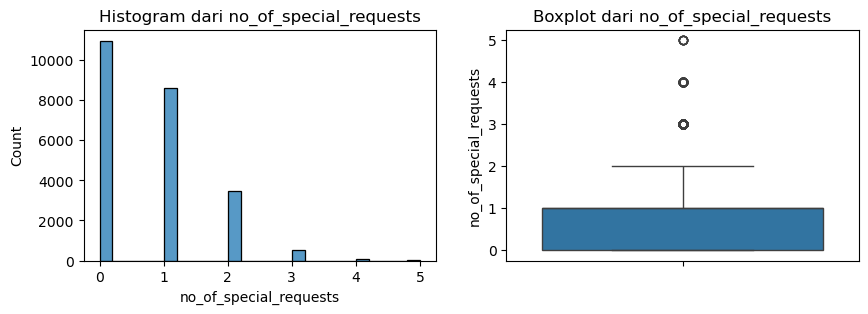

no_of_special_requests - Skewness: 0.9176104140055928
no_of_special_requests - Kurtosis: 0.4304874312393583


In [44]:
def check_distribution_outliers(df, num_cols):
    for col in num_cols:
        plt.figure(figsize=(10, 3))

        plt.subplot(1, 2, 1)
        sns.histplot(df[col], bins=25)
        plt.title(f'Histogram dari {col}')
        
        plt.subplot(1, 2, 2)
        sns.boxplot(y = df[col])
        plt.title(f'Boxplot dari {col}')
        
        plt.show()

        print(f'{col} - Skewness: {df[col].skew()}')
        print(f'{col} - Kurtosis: {df[col].kurt()}')
        
check_distribution_outliers(df[num_cols], num_cols)

Cek Normalitas 

In [45]:
for i in num_cols:
    print(i, shapiro(df[i]))

no_of_adults ShapiroResult(statistic=np.float64(0.6998525554628371), pvalue=np.float64(3.9064753572975015e-107))
no_of_children ShapiroResult(statistic=np.float64(0.33112020646503615), pvalue=np.float64(4.202875767330242e-129))
no_of_weekend_nights ShapiroResult(statistic=np.float64(0.793183121192399), pvalue=np.float64(1.2423177478326105e-97))
no_of_week_nights ShapiroResult(statistic=np.float64(0.8699926983727302), pvalue=np.float64(2.0424756154320175e-86))
required_car_parking_space ShapiroResult(statistic=np.float64(0.19754204391691232), pvalue=np.float64(2.197929397226429e-134))
lead_time ShapiroResult(statistic=np.float64(0.850897013474766), pvalue=np.float64(1.179630105641241e-89))
arrival_year ShapiroResult(statistic=np.float64(0.4269531626853299), pvalue=np.float64(1.0588391130353118e-124))
arrival_month ShapiroResult(statistic=np.float64(0.9467058999693696), pvalue=np.float64(7.907742474634091e-67))
arrival_date ShapiroResult(statistic=np.float64(0.9528925880673776), pvalue=n

c:\Users\lenovo\anaconda3\envs\deep_learning\lib\site-packages\scipy\stats\_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 23630.
  res = hypotest_fun_out(*samples, **kwds)


Menganalisis waktu tunggu vs status pemesanan

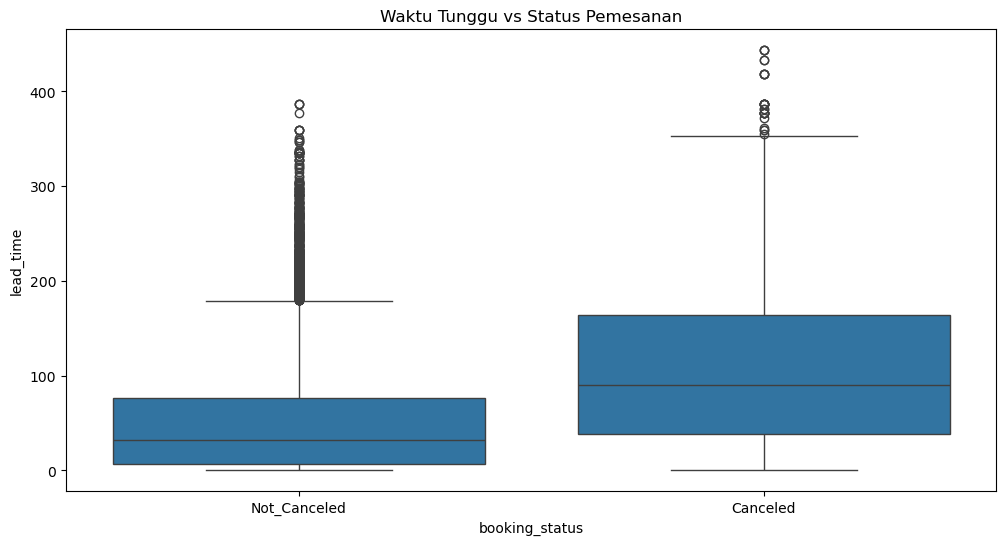

In [46]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='booking_status', y='lead_time', data=df)
plt.title('Waktu Tunggu vs Status Pemesanan')
plt.show()

Harga rata-rata per kamar vs status pemesanan

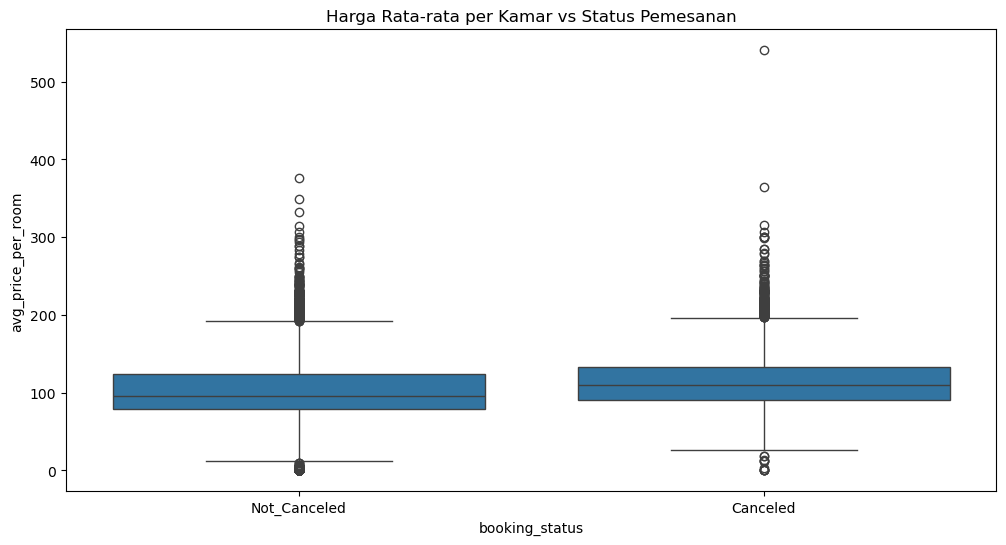

In [47]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='booking_status', y='avg_price_per_room', data=df)
plt.title('Harga Rata-rata per Kamar vs Status Pemesanan')
plt.show()

Hubungan antara permintaan khusus dan pembatalan

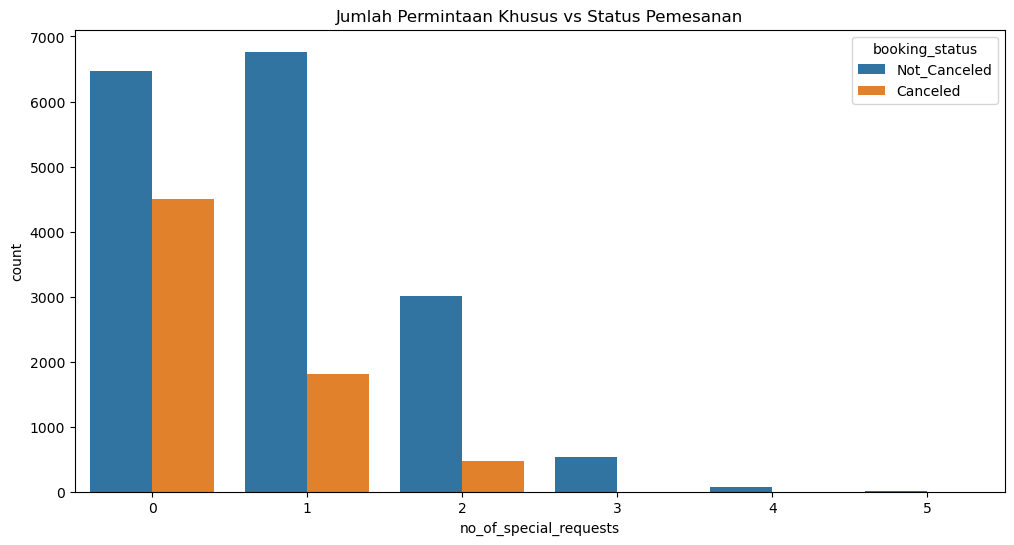

In [48]:
plt.figure(figsize=(12, 6))
sns.countplot(x='no_of_special_requests', hue='booking_status', data=df)
plt.title('Jumlah Permintaan Khusus vs Status Pemesanan')
plt.show()

Visualisasi Tipe kamar dan tingkat pembatalan

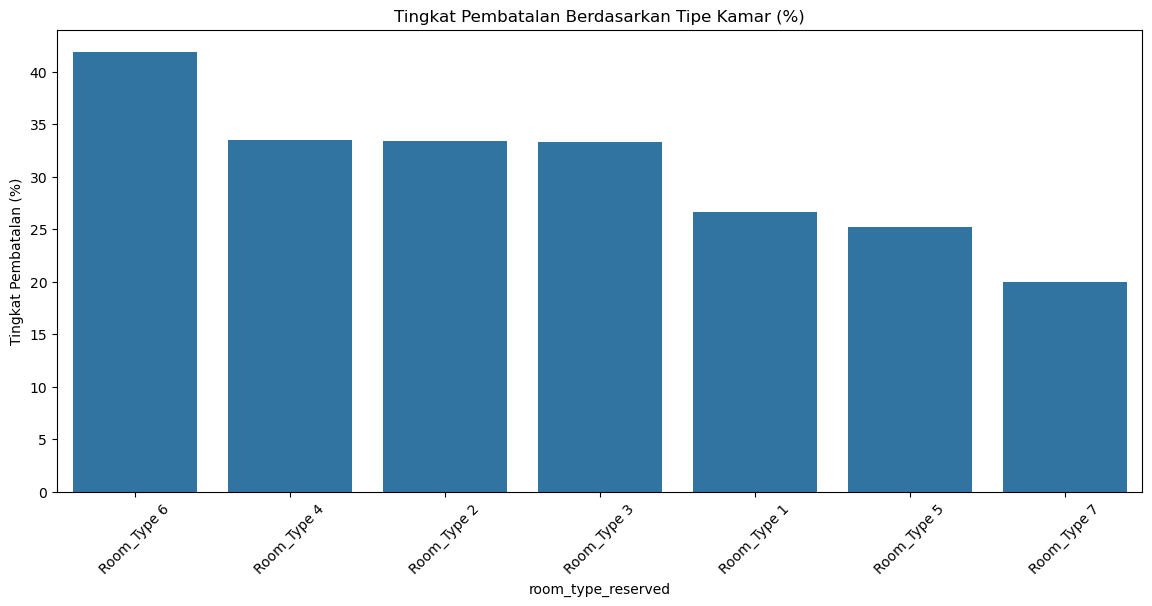

In [49]:
plt.figure(figsize=(14, 6))
cancellation_by_room = df.groupby('room_type_reserved')['booking_status'].apply(lambda x: (x == 'Canceled').mean() * 100)
cancellation_by_room = cancellation_by_room.reset_index().sort_values('booking_status', ascending=False)
sns.barplot(x='room_type_reserved', y='booking_status', data=cancellation_by_room)
plt.title('Tingkat Pembatalan Berdasarkan Tipe Kamar (%)')
plt.ylabel('Tingkat Pembatalan (%)')
plt.xticks(rotation=45)
plt.show()

Correlation Matrix

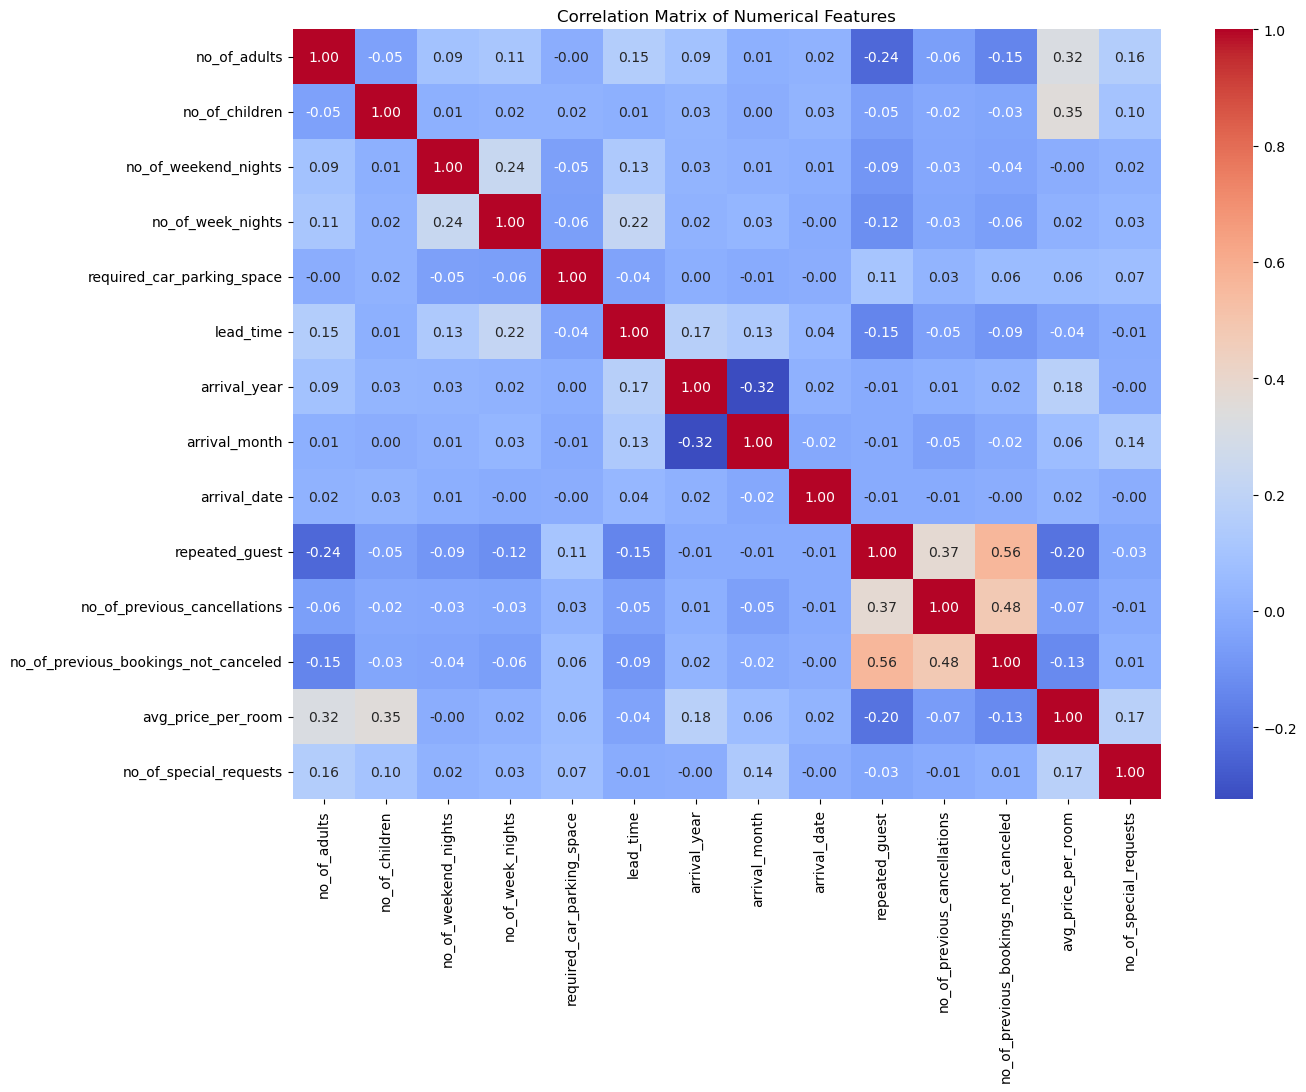

In [50]:
plt.figure(figsize=(14, 10))
correlation_matrix = df[num_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

### Preprocessing

Split Data

In [51]:
X = df.drop('booking_status', axis=1)
y = df['booking_status']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Encoding

In [52]:
le_target = LabelEncoder()
y_train = le_target.fit_transform(y_train)
y_test = le_target.transform(y_test)

In [53]:
cat_cols.remove('booking_status')

In [54]:
label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    X_train[col] = le.fit_transform(X_train[col])
    X_test[col] = le.transform(X_test[col])
    label_encoders[col] = le


Scaling

In [55]:
rb_scaler = RobustScaler()
X_train[num_cols] = rb_scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = rb_scaler.transform(X_test[num_cols])

### Modeling

Random Forest Model

In [56]:
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

In [57]:
print("Random Forest Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf)}")
print(classification_report(y_test, y_pred_rf))
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Results:
Accuracy: 0.8592890393567499
              precision    recall  f1-score   support

           0       0.78      0.70      0.74      1343
           1       0.88      0.92      0.90      3383

    accuracy                           0.86      4726
   macro avg       0.83      0.81      0.82      4726
weighted avg       0.86      0.86      0.86      4726

[[ 934  409]
 [ 256 3127]]


XGBoost Model

In [58]:
xgb_model = xgb.XGBClassifier(random_state=42)
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

In [59]:
print("XGBoost Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_xgb)}")
print(classification_report(y_test, y_pred_xgb))
print(confusion_matrix(y_test, y_pred_xgb))

XGBoost Results:
Accuracy: 0.8601354210749048
              precision    recall  f1-score   support

           0       0.77      0.72      0.75      1343
           1       0.89      0.92      0.90      3383

    accuracy                           0.86      4726
   macro avg       0.83      0.82      0.82      4726
weighted avg       0.86      0.86      0.86      4726

[[ 969  374]
 [ 287 3096]]


### Evaluasi

In [60]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)

if rf_accuracy > xgb_accuracy:
    best_model = rf_model
    print(f"Random Forest is better with accuracy: {rf_accuracy}")
else:
    best_model = xgb_model
    print(f"XGBoost is better with accuracy: {xgb_accuracy}")

XGBoost is better with accuracy: 0.8601354210749048


### Save Object

In [61]:
with open('models/hotel_booking_model.pkl', 'wb') as f:
    pickle.dump(best_model, f)
with open('models/label_encoders.pkl', 'wb') as f:
    pickle.dump(label_encoders, f)
with open('models/scaler.pkl', 'wb') as f:
    pickle.dump(rb_scaler, f)
with open('models/target_encoder.pkl', 'wb') as f:
    pickle.dump(le_target, f)
with open('models/feature_columns.pkl', 'wb') as f:
    pickle.dump(X_train.columns.tolist(), f)